In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA

In [6]:
#Create a sample student performance dataset
data = {
    'Study_Hours' : [2,4,6,8,10,3,7,9],
    'Attendance' : [50,60,70,80,90,55,75,85],
    'Assignment_Score': [40,50,60,75,90,45,70,85],
    'Internal_Marks' : [35,45,55,70,88,40,65,82]
}
df=pd.DataFrame(data)
print("Original Dataset:")
print(df)

Original Dataset:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0            2          50                40              35
1            4          60                50              45
2            6          70                60              55
3            8          80                75              70
4           10          90                90              88
5            3          55                45              40
6            7          75                70              65
7            9          85                85              82


In [22]:
#Create Min-Max Scaler
normalizer=MinMaxScaler()

#Normalize all features
normalized_data=normalizer.fit_transform(df)

#Convert the result into a DataFrame
normalized_df=pd.DataFrame(
    normalized_data,
    columns=df.columns
)
print("\nNormalized Dataset:")
print(normalized_df.round(2))



Normalized Dataset:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0         0.00        0.00               0.0            0.00
1         0.25        0.25               0.2            0.19
2         0.50        0.50               0.4            0.38
3         0.75        0.75               0.7            0.66
4         1.00        1.00               1.0            1.00
5         0.12        0.12               0.1            0.09
6         0.62        0.62               0.6            0.57
7         0.88        0.88               0.9            0.89


In [23]:
#Create the standard scaler
scaler = StandardScaler()

#Standardize all features
standardized_data=scaler.fit_transform(df)

#Convert the result into a dataframe
standardized_df=pd.DataFrame(
    standardized_data,
    columns=df.columns
)
print("\nStandardized Dataset:")
print(standardized_df.round(2))



Standardized Dataset:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0        -1.52       -1.52             -1.40           -1.37
1        -0.78       -0.78             -0.83           -0.82
2        -0.05       -0.05             -0.25           -0.27
3         0.69        0.69              0.61            0.55
4         1.43        1.43              1.47            1.53
5        -1.15       -1.15             -1.11           -1.10
6         0.32        0.32              0.32            0.27
7         1.06        1.06              1.19            1.20


In [10]:
print("\nMean of standardized features:")
print(standardized_df.mean().round(2))


Mean of standardized features:
Study_Hours         0.0
Attendance          0.0
Assignment_Score    0.0
Internal_Marks      0.0
dtype: float64


In [11]:
print("\nStandard deviation of standardized features:")
print(standardized_df.std(ddof=0).round(2))


Standard deviation of standardized features:
Study_Hours         1.0
Attendance          1.0
Assignment_Score    1.0
Internal_Marks      1.0
dtype: float64


In [24]:
#step 1 : standardize the data before PCA
scaler=StandardScaler()
X_scaled=scaler.fit_transform(df)

#step 2 : create pca with two components
pca = PCA(n_components=2)

#step 3 : Transform the standardized data
pca_data=pca.fit_transform(X_scaled)

#step 4: store the results in a dataframe
pca_df = pd.DataFrame(pca_data,columns=['Principal_Component_1','Principal_Component_2'])



In [25]:
print("\nPCA Transformed Dataset:")
print(pca_df.round(2))


PCA Transformed Dataset:
   Principal_Component_1  Principal_Component_2
0                  -2.91                   0.14
1                  -1.61                  -0.04
2                  -0.31                  -0.22
3                   1.27                  -0.12
4                   2.93                   0.08
5                  -2.26                   0.05
6                   0.62                  -0.03
7                   2.25                   0.14


In [26]:
#Display explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))



Explained Variance Ratio:
[0.9965 0.0034]


In [18]:
print("\n Total Variance Retained:")
print(round(pca.explained_variance_ratio_.sum()*100,2),"%")



 Total Variance Retained:
99.99 %


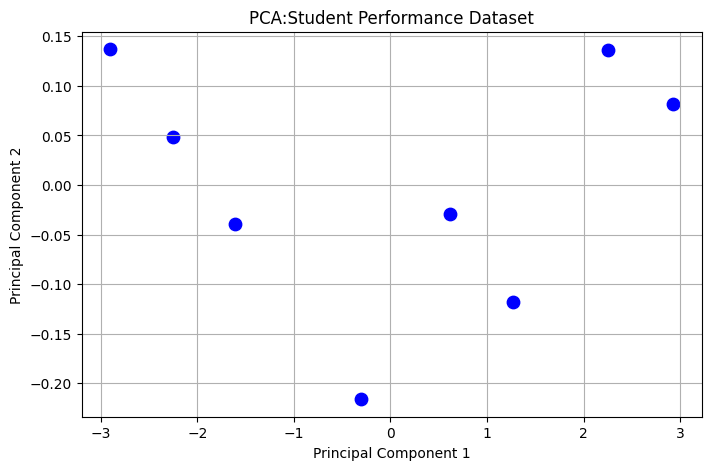

In [20]:
plt.figure(figsize=(8,5))
plt.scatter(
    pca_df['Principal_Component_1'],
    pca_df['Principal_Component_2'],
    color='blue',
    s=80
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA:Student Performance Dataset')
plt.grid(True)
plt.show()



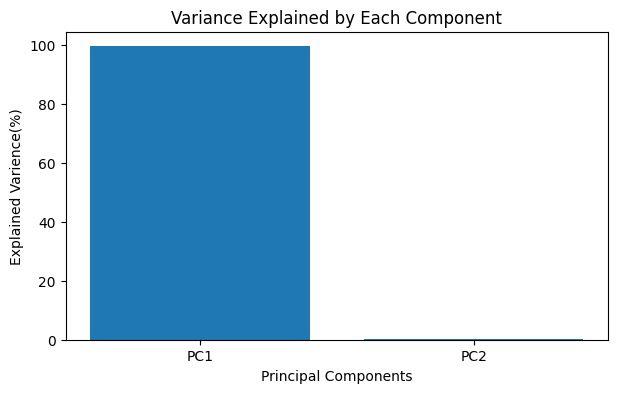

In [21]:
plt.figure(figsize=(7,4))
components=['PC1','PC2']

plt.bar(
    components,
    pca.explained_variance_ratio_*100
)
plt.xlabel('Principal Components')
plt.ylabel('Explained Varience(%)')
plt.title('Variance Explained by Each Component')
plt.show()